# Exploração: o problema dos cancelamentos

Este notebook descreve o problema de negócio antes do modelo. Ele responde a quatro perguntas, e cada resposta alimenta um slide:

1. **Qual o tamanho do problema?** Quantas reservas e quanta receita são canceladas (slide 1).
2. **Quando os cancelamentos acontecem?** Quanto tempo o hotel tem para agir (slide 4).
3. **Onde eles se concentram?** Os grupos de maior risco (slide 3).
4. **Que régua o modelo precisa vencer?** Regras simples que o hotel poderia usar hoje (slide 3).

**Atenção:** as seções 2 e 4 usam `reservation_status` e `reservation_status_date`, que só existem depois do cancelamento. Aqui elas servem **apenas para descrever quando** os cancelamentos acontecem. Nunca entram como variáveis do modelo (ver o dicionário de dados).

Legendas dos títulos:

* <code style="color:green">verde</code>: explicação
* <code style="color:purple">roxo</code>: comentário, decisão
* <code style="color:gray">cinza</code>: contexto de negócio

**Roteiro**

0. Pacotes, funções e estilo dos gráficos
1. Leitura e escopo
2. A linha do tempo de uma reserva
3. O tamanho do problema
4. Quando os cancelamentos acontecem
5. Onde os cancelamentos se concentram
6. 2017 é diferente
7. A régua do modelo: regras simples
8. Resumo para a apresentação

**Como rodar:** abra este notebook de dentro da pasta `analise/`. A base é lida de `../dados/hotel_bookings.csv`.

## 0. Pacotes, funções e estilo dos gráficos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter
from IPython.display import display

import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

# paleta: duas cores de série, tintas para texto, grade e eixo
AZUL, LARANJA = '#257de0', '#f47230'
TINTA, TINTA2, GRADE, EIXO = '#191919', '#666666', '#e7e7e7', '#c2c2c2'
plt.rcParams.update({
    'figure.dpi': 100, 'font.family': ['Segoe UI', 'DejaVu Sans'], 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': EIXO,
    'axes.titlesize': 11, 'axes.titlecolor': TINTA, 'axes.titlelocation': 'left',
    'axes.labelcolor': TINTA2, 'xtick.color': TINTA2, 'ytick.color': TINTA2,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': GRADE, 'grid.linewidth': 0.8,
    'axes.axisbelow': True, 'legend.frameon': False, 'legend.labelcolor': TINTA2,
})

Y = 'is_canceled'

def taxa_resposta(base, variavel, y=Y):
    """Para cada nível: n, % da base, taxa de cancelamento e % de todos os cancelamentos que vêm dali."""
    t = base.groupby(variavel, observed=True, dropna=False).agg(n=(y, 'size'), canceladas=(y, 'sum'), taxa=(y, 'mean'))
    t['pct_base'] = t['n'] / t['n'].sum()
    t['pct_cancelamentos'] = t['canceladas'] / t['canceladas'].sum()
    return t[['n', 'pct_base', 'taxa', 'pct_cancelamentos']]

pct = PercentFormatter(1.0, decimals=0)

## 1. Leitura e escopo

In [2]:
hotel = pd.read_csv('../dados/hotel_bookings.csv')

# datas da linha do tempo de cada reserva
hotel['chegada'] = pd.to_datetime(hotel['arrival_date_year'].astype(str) + '-' + hotel['arrival_date_month']
                                  + '-' + hotel['arrival_date_day_of_month'].astype(str), format='%Y-%B-%d')
hotel['data_reserva'] = hotel['chegada'] - pd.to_timedelta(hotel['lead_time'], unit='D')
hotel['data_status'] = pd.to_datetime(hotel['reservation_status_date'])

# receita reservada = diária média x noites (o que o hotel esperava receber pela reserva)
hotel['noites'] = hotel['stays_in_weekend_nights'] + hotel['stays_in_week_nights']
hotel['receita'] = hotel['adr'] * hotel['noites']

ESCOPO = 'sem_deposito'   # troque para 'todas' para refazer com a base inteira
base = hotel[hotel['deposit_type'] == 'No Deposit'].copy() if ESCOPO == 'sem_deposito' else hotel.copy()
print(ESCOPO, base.shape, '| taxa de cancelamento:', round(base[Y].mean(), 4))

sem_deposito (104641, 37) | taxa de cancelamento: 0.2838


### <code style="color:purple">COMENTÁRIOS:</code>

- **104.641 reservas sem depósito**, com 28,4% de cancelamento.
- Duas colunas novas: `data_reserva` (chegada menos antecedência) e `receita` (diária média × noites). A receita reservada é o que o hotel esperava receber pela reserva, não o faturamento. A base não informa a moeda.

## 2. A linha do tempo de uma reserva

### <code style="color:green">Cada linha conta a vida inteira de uma reserva, registrada no fim dela</code>

```
 reserva entra ─────────── antecedência (lead_time) ───────────► chegada
      │                                                             │
  o modelo decide aqui                                     ├─ veio (Check-Out)
      │                                                    └─ não veio (No-Show)
      ├─ alterações, pedidos especiais, vaga, quarto trocado...
      └─ cancelamento (reservation_status_date)
```

A data da reserva não vem na base: ela é a data de chegada menos a antecedência.

In [3]:
datas = pd.DataFrame({
    'primeira': [base['data_reserva'].min(), base['chegada'].min(), base['data_status'].min()],
    'última': [base['data_reserva'].max(), base['chegada'].max(), base['data_status'].max()],
}, index=['data da reserva', 'data de chegada', 'data do último status'])
display(datas.apply(lambda c: c.dt.date))
base['reservation_status'].value_counts().rename('reservas').to_frame()

,primeira,última
data da reserva,2013-06-24,2017-08-31
data de chegada,2015-07-01,2017-08-31
data do último status,2014-10-17,2017-09-14


,reservas
reservation_status,
Check-Out,74947
Canceled,28522
No-Show,1172


### <code style="color:purple">COMENTÁRIOS:</code>

- As reservas foram feitas de junho de 2013 a agosto de 2017, para chegadas de julho de 2015 a agosto de 2017: algumas entraram dois anos antes da chegada.
- 74.947 hóspedes vieram, 28.522 cancelaram avisando e 1.172 não apareceram (no-show).

## 3. O tamanho do problema

In [4]:
cancelada = base[Y] == 1
tamanho = pd.Series({
    'reservas': len(base),
    'canceladas (inclui no-show)': cancelada.sum(),
    '% das reservas canceladas': cancelada.mean(),
    'receita reservada': base['receita'].sum(),
    'receita das reservas canceladas': base.loc[cancelada, 'receita'].sum(),
    '% da receita reservada que foi cancelada': base.loc[cancelada, 'receita'].sum() / base['receita'].sum(),
    'receita média por reserva cancelada': base.loc[cancelada, 'receita'].mean(),
    'receita média por reserva mantida': base.loc[~cancelada, 'receita'].mean(),
    'noites médias, canceladas': base.loc[cancelada, 'noites'].mean(),
    'noites médias, mantidas': base.loc[~cancelada, 'noites'].mean(),
})
tamanho.to_frame('valor')

,valor
reservas,"104,641.000"
canceladas (inclui no-show),"29,694.000"
% das reservas canceladas,0.284
receita reservada,"39,053,065.250"
receita das reservas canceladas,"13,102,901.920"
% da receita reservada que foi cancelada,0.336
receita média por reserva cancelada,441.264
receita média por reserva mantida,346.247
"noites médias, canceladas",3.862
"noites médias, mantidas",3.394


,reservas,% das reservas,% da receita
2015 (jul–dez),"18,325.000",0.245,0.250
2016,"49,782.000",0.273,0.324
2017 (jan–ago),"36,534.000",0.318,0.381


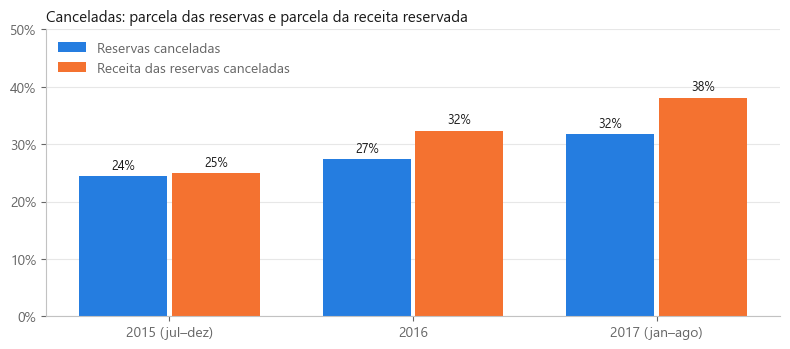

In [5]:
por_ano = base.groupby('arrival_date_year').apply(lambda g: pd.Series({
    'reservas': len(g),
    '% das reservas': g[Y].mean(),
    '% da receita': g.loc[g[Y] == 1, 'receita'].sum() / g['receita'].sum(),
}))
por_ano.index = ['2015 (jul–dez)', '2016', '2017 (jan–ago)']
display(por_ano)

fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(por_ano))
largura = 0.36
series = [(-largura / 2 - 0.01, '% das reservas', AZUL, 'Reservas canceladas'),
          (largura / 2 + 0.01, '% da receita', LARANJA, 'Receita das reservas canceladas')]
for desloc, col, cor, nome in series:
    barras = ax.bar(x + desloc, por_ano[col], largura, color=cor, label=nome)
    ax.bar_label(barras, labels=[f'{v:.0%}' for v in por_ano[col]], padding=3, color=TINTA, fontsize=9)
ax.set_xticks(x, por_ano.index)
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, 0.5)
ax.set_title('Canceladas: parcela das reservas e parcela da receita reservada')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

In [6]:
base.groupby('hotel').apply(lambda g: pd.Series({
    'reservas': len(g),
    '% das reservas': g[Y].mean(),
    '% da receita': g.loc[g[Y] == 1, 'receita'].sum() / g['receita'].sum(),
}))

,reservas,% das reservas,% da receita
hotel,,,
City Hotel,"66,442.000",0.305,0.349
Resort Hotel,"38,199.000",0.247,0.318


### <code style="color:purple">COMENTÁRIOS:</code>

- **28,4% das reservas foram canceladas, mas elas somam 33,6% da receita reservada.** As canceladas são reservas maiores: 441 em média, contra 346 das mantidas, em parte porque são mais longas (3,9 noites contra 3,4).
- **O problema cresce:** de 24,5% das reservas e 25,0% da receita no segundo semestre de 2015 para 31,8% e 38,1% de janeiro a agosto de 2017.
- No hotel urbano, 30,5% das reservas e 34,9% da receita; no resort, 24,7% e 31,8%.
- **Ressalva:** a receita das canceladas não é toda perdida, porque parte dos quartos é revendida. É receita **em risco**, não perda.

## 4. Quando os cancelamentos acontecem

### <code style="color:green">Duas medidas de tempo</code>

- **Dias antes da chegada:** quanto tempo antes da data de chegada o cliente avisou. Quanto maior, mais tempo o hotel tem para revender o quarto.
- **Dias depois de reservar:** quanto tempo depois de fazer a reserva o cliente desistiu. Diz quanto tempo uma ação feita logo após a reserva tem para funcionar.

Os no-shows ficam de fora desta seção: eles não avisam.

In [7]:
canc = base[base['reservation_status'] == 'Canceled'].copy()
canc['dias_antes_da_chegada'] = (canc['chegada'] - canc['data_status']).dt.days
canc['dias_depois_de_reservar'] = (canc['data_status'] - canc['data_reserva']).dt.days
print('Cancelamentos com aviso:', len(canc), '| no-shows:', (base['reservation_status'] == 'No-Show').sum())

display(canc[['dias_antes_da_chegada', 'dias_depois_de_reservar']].describe(percentiles=[.1, .25, .5, .75, .9]).T)

aviso = pd.Series({f'{d} dias ou mais': (canc['dias_antes_da_chegada'] >= d).mean() for d in [1, 7, 14, 30, 60, 90]},
                  name='% dos cancelamentos avisados com essa antecedência')
aviso.to_frame()

Cancelamentos com aviso: 28522 | no-shows: 1172


,count,mean,std,min,10%,25%,50%,75%,90%,max
dias_antes_da_chegada,"28,522.000",65.122,71.346,0.000,4.000,12.000,37.000,95.000,174.000,406.000
dias_depois_de_reservar,"28,522.000",48.403,71.533,0.000,0.000,2.000,15.000,67.000,145.000,502.000


,% dos cancelamentos avisados com essa antecedência
1 dias ou mais,0.970
7 dias ou mais,0.851
14 dias ou mais,0.734
30 dias ou mais,0.561
60 dias ou mais,0.374
90 dias ou mais,0.266


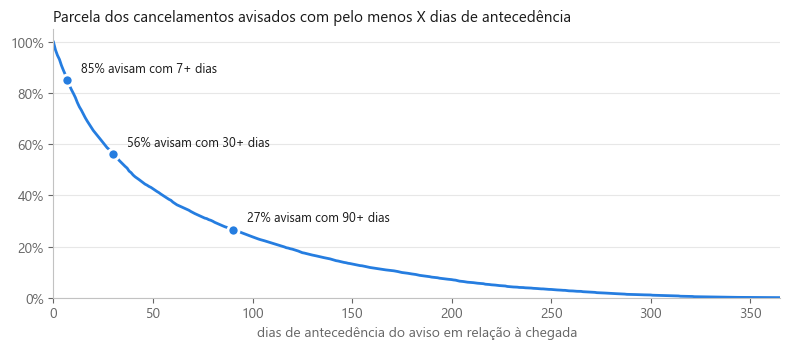

In [8]:
dias = np.arange(0, 366)
curva = [(canc['dias_antes_da_chegada'] >= d).mean() for d in dias]

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(dias, curva, color=AZUL, linewidth=2)
for d in [7, 30, 90]:
    v = curva[d]
    ax.plot([d], [v], 'o', color=AZUL, markersize=8, markeredgecolor='white', markeredgewidth=2)
    ax.annotate(f'{v:.0%} avisam com {d}+ dias', (d, v), xytext=(10, 6), textcoords='offset points', color=TINTA, fontsize=9)
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, 1.05)
ax.set_xlim(0, 365)
ax.set_xlabel('dias de antecedência do aviso em relação à chegada')
ax.set_title('Parcela dos cancelamentos avisados com pelo menos X dias de antecedência')
plt.tight_layout()
plt.show()

In [9]:
print('% cancelado até 2 dias depois de reservar:', round((canc['dias_depois_de_reservar'] <= 2).mean(), 3))
print('% cancelado até 7 dias depois de reservar:', round((canc['dias_depois_de_reservar'] <= 7).mean(), 3))

faixas = [-1, 7, 30, 90, 180, np.inf]
nomes = ['ate_7d', '8_30d', '31_90d', '91_180d', 'mais_180d']
canc['faixa_antecedencia'] = pd.cut(canc['lead_time'], faixas, labels=nomes)
canc.groupby('faixa_antecedencia', observed=True).agg(
    cancelamentos=('lead_time', 'size'),
    mediana_dias_antes_da_chegada=('dias_antes_da_chegada', 'median'),
    mediana_dias_depois_de_reservar=('dias_depois_de_reservar', 'median'),
)

% cancelado até 2 dias depois de reservar: 0.26
% cancelado até 7 dias depois de reservar: 0.398


,cancelamentos,mediana_dias_antes_da_chegada,mediana_dias_depois_de_reservar
faixa_antecedencia,,,
ate_7d,1469,1.000,0.000
8_30d,4537,11.000,4.000
31_90d,8471,34.000,14.000
91_180d,7523,85.000,40.000
mais_180d,6522,140.000,98.000


### <code style="color:purple">COMENTÁRIOS:</code>

- **Em mediana, o cancelamento chega 37 dias antes da chegada.** 85% avisam com uma semana ou mais, 56% com um mês ou mais e 27% com três meses ou mais. Só 3% avisam no dia da chegada ou depois, e os 1.172 no-shows nem avisam.
- **Contando a partir da reserva, a desistência vem cedo:** mediana de 15 dias; 26% cancelam até 2 dias depois de reservar, e 40% em até uma semana.
- Quanto maior a antecedência, mais cedo vem o aviso: reservas feitas com mais de 180 dias cancelam, em mediana, 140 dias antes da chegada.
- O que isso diz para a recomendação:
  - em geral, há tempo para agir e para revender o quarto. O prejuízo maior está nos cancelamentos de última hora e nos no-shows;
  - uma ação logo depois da reserva (pedir depósito, confirmar) chega a tempo para a maioria. Mas um quarto dos cancelamentos acontece nos dois primeiros dias, antes de qualquer ligação: para esses, só uma regra aplicada na hora da reserva funciona.

## 5. Onde os cancelamentos se concentram

### <code style="color:green">Como ler as tabelas</code>

`taxa` é a parcela de reservas canceladas no grupo. `pct_cancelamentos` é a parcela de **todos** os cancelamentos que vêm daquele grupo. Um grupo importa para a decisão quando as duas são altas: cancela muito e é grande.

,n,pct_base,taxa,pct_cancelamentos
faixa_antecedencia,,,,
ate_7d,19619,0.187,0.092,0.061
8_30d,18438,0.176,0.260,0.162
31_90d,27139,0.259,0.322,0.294
91_180d,22260,0.213,0.349,0.261
mais_180d,17185,0.164,0.384,0.222


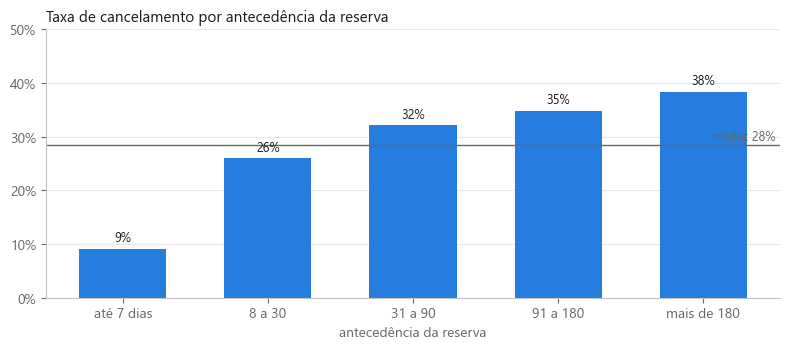

In [10]:
base['faixa_antecedencia'] = pd.cut(base['lead_time'], faixas, labels=nomes)
t = taxa_resposta(base, 'faixa_antecedencia')
display(t)

rotulos = ['até 7 dias', '8 a 30', '31 a 90', '91 a 180', 'mais de 180']
fig, ax = plt.subplots(figsize=(8, 3.6))
barras = ax.bar(rotulos, t['taxa'], color=AZUL, width=0.6)
ax.bar_label(barras, labels=[f'{v:.0%}' for v in t['taxa']], padding=3, color=TINTA, fontsize=9)
media = base[Y].mean()
ax.axhline(media, color=TINTA2, linewidth=1)
ax.annotate(f'média: {media:.0%}', (len(t) - 0.5, media), xytext=(0, 4), textcoords='offset points',
            ha='right', color=TINTA2, fontsize=9)
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, 0.5)
ax.set_xlabel('antecedência da reserva')
ax.set_title('Taxa de cancelamento por antecedência da reserva')
plt.tight_layout()
plt.show()

In [11]:
temporada = {'July': 'jul_ago', 'August': 'jul_ago', 'April': 'abr_jun', 'May': 'abr_jun', 'June': 'abr_jun'}
base['temporada'] = base['arrival_date_month'].map(temporada).fillna('set_mar')

for var in ['market_segment', 'hotel', 'temporada', 'customer_type']:
    print(f'\n--- {var}')
    display(taxa_resposta(base, var).sort_values('n', ascending=False))


--- market_segment


,n,pct_base,taxa,pct_cancelamentos
market_segment,,,,
Online TA,56403,0.539,0.366,0.696
Offline TA/TO,19209,0.184,0.172,0.111
Direct,12581,0.120,0.152,0.065
Groups,10509,0.100,0.283,0.100
Corporate,4957,0.047,0.137,0.023
Complementary,743,0.007,0.131,0.003
Aviation,237,0.002,0.219,0.002
Undefined,2,0.000,1.000,0.000



--- hotel


,n,pct_base,taxa,pct_cancelamentos
hotel,,,,
City Hotel,66442,0.635,0.305,0.682
Resort Hotel,38199,0.365,0.247,0.318



--- temporada


,n,pct_base,taxa,pct_cancelamentos
temporada,,,,
set_mar,51129,0.489,0.249,0.428
abr_jun,28570,0.273,0.300,0.289
jul_ago,24942,0.238,0.337,0.283



--- customer_type


,n,pct_base,taxa,pct_cancelamentos
customer_type,,,,
Transient,76684,0.733,0.308,0.794
Transient-Party,23858,0.228,0.224,0.180
Contract,3530,0.034,0.203,0.024
Group,569,0.005,0.104,0.002


### <code style="color:purple">COMENTÁRIOS:</code>

- **Antecedência:** uma escada de 9% (até 7 dias) a 38% (mais de 180 dias). As reservas com mais de 30 dias de antecedência são 64% da base e trazem 78% dos cancelamentos.
- **Segmento:** a agência online tem 54% das reservas e **70% dos cancelamentos** (taxa de 36,6%). É onde está o volume do problema.
- **Hotel:** o urbano tem 64% das reservas e 68% dos cancelamentos.
- **Temporada:** julho e agosto, 33,7%; abril a junho, 30,0%; setembro a março, 24,9%.
- **Tipo de cliente:** o avulso (Transient) tem 73% das reservas e 79% dos cancelamentos.
- O centro do problema é a **reserva feita com antecedência por agência online**. A seção 7 testa exatamente essa ideia como regra.

## 6. 2017 é diferente

### <code style="color:green">Por que isso importa</code>

O modelo vai aprender com as chegadas de 2015 e 2016 e ser testado nas de 2017, como aconteceria na vida real: treina-se com o passado e usa-se no futuro. Se 2017 cancela mais, o teste fica mais difícil, e as probabilidades do modelo podem sair baixas demais para 2017.

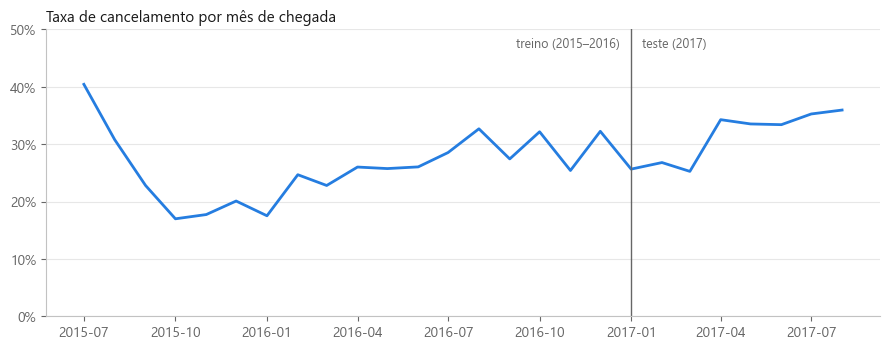

In [12]:
mensal = base.groupby(base['chegada'].dt.to_period('M'))[Y].agg(['size', 'mean'])
mensal.index = mensal.index.to_timestamp()

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(mensal.index, mensal['mean'], color=AZUL, linewidth=2)
inicio_teste = pd.Timestamp('2017-01-01')
ax.axvline(inicio_teste, color=TINTA2, linewidth=1)
ax.annotate('treino (2015–2016)', (inicio_teste, 0.47), xytext=(-8, 0), textcoords='offset points', ha='right', color=TINTA2, fontsize=9)
ax.annotate('teste (2017)', (inicio_teste, 0.47), xytext=(8, 0), textcoords='offset points', ha='left', color=TINTA2, fontsize=9)
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, 0.5)
ax.set_title('Taxa de cancelamento por mês de chegada')
plt.tight_layout()
plt.show()

In [13]:
treino = base[base['arrival_date_year'] < 2017]
teste = base[base['arrival_date_year'] == 2017]
mesmos_meses = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August']
jan_ago_2016 = base[(base['arrival_date_year'] == 2016) & base['arrival_date_month'].isin(mesmos_meses)]

pd.DataFrame({
    'reservas': [len(treino), len(teste), len(jan_ago_2016)],
    'taxa de cancelamento': [treino[Y].mean(), teste[Y].mean(), jan_ago_2016[Y].mean()],
}, index=['treino: 2015 e 2016', 'teste: 2017 (jan–ago)', 'comparação: 2016 (jan–ago)'])

,reservas,taxa de cancelamento
treino: 2015 e 2016,68107,0.266
teste: 2017 (jan–ago),36534,0.318
comparação: 2016 (jan–ago),32317,0.262


### <code style="color:purple">COMENTÁRIOS:</code>

- A taxa muda bastante ao longo do tempo: começa alta em julho de 2015 (o primeiro mês da base), cai para perto de 17% a 20% no fim de 2015 e sobe até 34% a 36% em meados de 2017.
- **Treino (2015 e 2016): 26,6%. Teste (2017): 31,8%.** Nos mesmos meses de 2016 (janeiro a agosto), a taxa era 26,2%: a alta de 2017 não é só efeito da época do ano.
- Consequências:
  - para **ordenar** (a lista de ligação), o que importa é o modelo colocar as reservas certas no topo, e a alta geral atrapalha pouco;
  - para **estimar** (overbooking), as probabilidades tendem a sair baixas em 2017. É preciso conferir a calibração no teste;
  - no anexo técnico, a mudança entra como limitação.

## 7. A régua do modelo: regras simples

### <code style="color:green">O que o modelo precisa vencer</code>

Um hotel não precisa de modelo para desconfiar de reservas feitas com muita antecedência por agência online. Por isso, o modelo só se justifica se encontrar **mais cancelamentos do que uma regra simples, ligando para o mesmo número de reservas**.

As regras abaixo usam só variáveis conhecidas na hora da reserva, e são medidas no **ano de teste (2017)**, o mesmo em que o modelo será avaliado. Para cada regra:

- `pct_marcadas`: parcela das reservas que a regra mandaria contatar;
- `taxa_nas_marcadas`: quantas dessas reservas de fato cancelaram;
- `pct_cancelamentos_pegos`: parcela de todos os cancelamentos de 2017 que a regra encontra;
- `lift`: quantas vezes a taxa nas marcadas supera a taxa geral.

In [14]:
def avaliar_regra(base, marcada):
    return pd.Series({
        'pct_marcadas': marcada.mean(),
        'taxa_nas_marcadas': base.loc[marcada, Y].mean(),
        'pct_cancelamentos_pegos': base.loc[marcada, Y].sum() / base[Y].sum(),
        'lift': base.loc[marcada, Y].mean() / base[Y].mean(),
    })

online = teste['market_segment'] == 'Online TA'
regras = {
    'antecedência acima de 30 dias': teste['lead_time'] > 30,
    'antecedência acima de 90 dias': teste['lead_time'] > 90,
    'agência online': online,
    'agência online e antecedência acima de 30 dias': online & (teste['lead_time'] > 30),
    'agência online e antecedência acima de 90 dias': online & (teste['lead_time'] > 90),
}
regua = pd.DataFrame({nome: avaliar_regra(teste, m) for nome, m in regras.items()}).T.sort_values('pct_marcadas')
regua

,pct_marcadas,taxa_nas_marcadas,pct_cancelamentos_pegos,lift
agência online e antecedência acima de 90 dias,0.282,0.506,0.450,1.594
agência online e antecedência acima de 30 dias,0.441,0.476,0.661,1.498
antecedência acima de 90 dias,0.443,0.395,0.551,1.244
agência online,0.619,0.408,0.796,1.285
antecedência acima de 30 dias,0.673,0.381,0.807,1.200


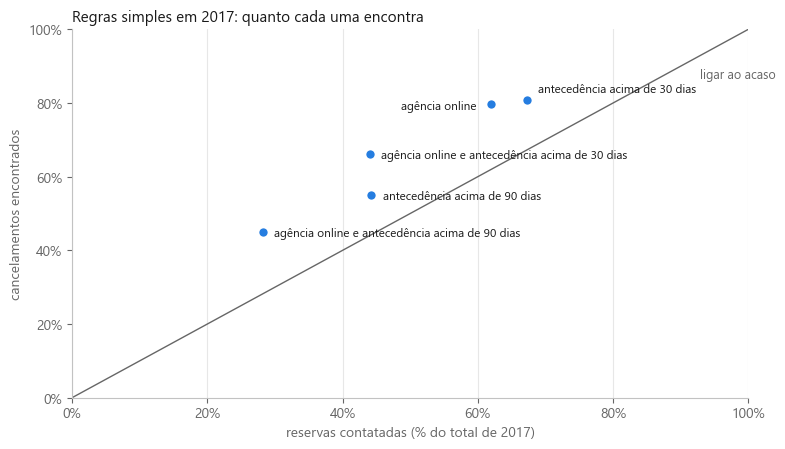

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot([0, 1], [0, 1], color=TINTA2, linewidth=1)
ax.annotate('ligar ao acaso', (0.92, 0.92), xytext=(4, -14), textcoords='offset points', color=TINTA2, fontsize=9)
ax.plot(regua['pct_marcadas'], regua['pct_cancelamentos_pegos'], 'o', color=AZUL, markersize=8,
        markeredgecolor='white', markeredgewidth=2)
# posição de cada rótulo (deslocamento em pontos e alinhamento), para não encostar nos vizinhos
posicao = {'agência online': ((-10, -3), 'right'), 'antecedência acima de 30 dias': ((8, 6), 'left')}
for nome, linha in regua.iterrows():
    desloc, alinha = posicao.get(nome, ((8, -3), 'left'))
    ax.annotate(nome, (linha['pct_marcadas'], linha['pct_cancelamentos_pegos']), xytext=desloc, ha=alinha,
                textcoords='offset points', color=TINTA, fontsize=8.5)
ax.xaxis.set_major_formatter(pct)
ax.yaxis.set_major_formatter(pct)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(axis='both')
ax.set_xlabel('reservas contatadas (% do total de 2017)')
ax.set_ylabel('cancelamentos encontrados')
ax.set_title('Regras simples em 2017: quanto cada uma encontra')
plt.tight_layout()
plt.show()

### <code style="color:purple">COMENTÁRIOS:</code>

- Em 2017, 31,8% das reservas foram canceladas.
- **"Agência online e antecedência acima de 30 dias"** marca 44% das reservas; 47,6% delas cancelam, e a regra encontra **66% dos cancelamentos** (lift de 1,5). Ligando ao acaso para 44% das reservas, seriam encontrados 44%.
- **"Agência online e antecedência acima de 90 dias"** marca 28% das reservas, com taxa de 50,6%, e encontra 45% dos cancelamentos (lift de 1,6).
- **A régua do modelo:** ligando para as 28% reservas de maior risco, ele precisa encontrar mais de 45% dos cancelamentos; ligando para 44%, mais de 66%. No gráfico, a curva de ganho do modelo precisa passar acima desses pontos.
- Se não passar, a recomendação passa a ser a regra simples. Isso também é um resultado.

## 8. Resumo para a apresentação

### <code style="color:purple">O que levar para os slides</code>

- **Slide 1, o tamanho do problema:** 28% das reservas sem garantia de pagamento são canceladas, e elas levam 34% da receita reservada. Em 2017, foram 38% da receita.
- **Slide 3, onde se concentra:** reservas feitas com mais de 30 dias de antecedência são 64% da base e trazem 78% dos cancelamentos; a agência online tem 54% das reservas e 70% dos cancelamentos.
- **Slide 3, a régua:** a regra "agência online e mais de 30 dias de antecedência" encontra 66% dos cancelamentos contatando 44% das reservas. O modelo precisa fazer melhor que isso.
- **Slide 4, quando agir:** 85% dos cancelamentos são avisados com uma semana ou mais de antecedência, mas um quarto acontece nos dois primeiros dias depois da reserva. A ação vem logo depois da reserva, e o depósito funciona como regra na hora da reserva para as de maior risco.
- **Anexo, limitações:** 2017 cancela mais que o período de treino (31,8% contra 26,6%); receita em risco não é perda, por causa da revenda; as colunas de status foram usadas só para descrever o tempo dos cancelamentos, nunca no modelo.